#### 09B · Validación del emulador final (PVAR → XGBoost → ruido)
Compara la Hs horaria observada (1985–2025) con las 100 simulaciones del 08.

- Cada simulación (1941–2026) se parte en **bloques de la misma longitud que la observación** (41 años → 2 bloques por simulación, 200 en total). Las bandas son p5–p95 entre bloques: así la variabilidad muestral es comparable a la de un registro de 41 años.
- Secciones: 1. régimen medio · 2. persistencia y autocorrelación · 3. estacionalidad (y ciclo diario) · 4. variabilidad interanual · 5. extremos · 6. resumen.
- Los estadísticos se guardan en `validacion{SUF}.pkl` para no recalcular.

In [8]:
import glob, os, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genextreme
from scipy.signal import find_peaks

In [9]:
#### Configuración
point = "p102"
SUF = "_simple_est_fqm"                                     # "" = ruido completo, "_simple" = simplificado
carpeta = f"outputs/xgb_pit_{point}/emulador{SUF}"
fichero_val = f"outputs/xgb_pit_{point}/validacion{SUF}.pkl"
os.makedirs("figuras", exist_ok=True)

obs = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"].loc["1985":"2025"].dropna()
N_ANOS = obs.index.year.nunique()                   # longitud de cada bloque simulado
ficheros = sorted(glob.glob(f"{carpeta}/sim_*.parquet"))

U90, U99 = obs.quantile(0.90), obs.quantile(0.99)   # umbrales fijos (observados) para duraciones y temporales
Q_FINO = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), 1 - np.logspace(-2, -4.5, 26)]))
Q_TABLA = [0.5, 0.9, 0.99, 0.999]
LAGS = np.arange(0, 241)                            # hasta 10 días
T_RET = [2, 10, 50, 100]
print(f"obs: {N_ANOS} años | {len(ficheros)} simulaciones | U90 = {U90:.2f} m, U99 = {U99:.2f} m")

obs: 41 años | 20 simulaciones | U90 = 1.91 m, U99 = 3.73 m


In [10]:
#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

def banda(ax, x, arr, color=AZUL, label="sim. p5–p95", mediana=True):
    """Banda p5–p95 (y mediana) entre bloques simulados; arr con forma (bloque, x)."""
    p5, p50, p95 = np.nanpercentile(arr, [5, 50, 95], axis=0)
    ax.fill_between(x, p5, p95, color=color, alpha=0.25, lw=0, label=label)
    if mediana:
        ax.plot(x, p50, color=color, lw=1.5, label="sim. mediana")

#### Estadísticos de un bloque (se aplica igual a la observación y a cada bloque simulado)

In [11]:
def acf(s, lags):
    """Autocorrelación de la serie horaria (con huecos como NaN)."""
    x = s.asfreq("h").values.astype("float64")
    x = x - np.nanmean(x)
    v = np.nanmean(x * x)
    return np.array([1.0 if l == 0 else np.nanmean(x[:-l] * x[l:]) / v for l in lags])

def duraciones(s, u):
    """Duración (h) de cada racha continua por encima de u."""
    sobre = np.concatenate([[0], (s.asfreq("h").values > u).astype(int), [0]])
    d = np.diff(sobre)
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

def gev_niveles(am):
    c, loc, sc = genextreme.fit(am)
    return {"xi": -c, **{f"Hs{T}": genextreme.isf(1 / T, c, loc, sc) for T in T_RET}}

def estadisticos(s):
    """s: Hs horaria de un bloque de N_ANOS años completos."""
    anual = s.groupby(s.index.year)
    am = anual.max().values
    picos, _ = find_peaks(s.values, height=U99, distance=72)
    media_anual = anual.mean().values
    return {
        "q": s.quantile(Q_FINO).values,
        "media": s.mean(), "std": s.std(),
        "acf": acf(s, LAGS),
        "dur90": duraciones(s, U90),
        "mes_media": s.groupby(s.index.month).mean().values,
        "mes_q90": s.groupby(s.index.month).quantile(0.90).values,
        "mes_q99": s.groupby(s.index.month).quantile(0.99).values,
        "mes_max": s.groupby([s.index.year, s.index.month]).max().groupby(level=1).mean().values,
        "hora_media": s.groupby(s.index.hour).mean().values,
        "anual_media": media_anual, "anual_q95": anual.quantile(0.95).values,
        "std_anual_media": media_anual.std(), "std_anual_q95": anual.quantile(0.95).std(),
        "ac1_anual_media": np.corrcoef(media_anual[:-1], media_anual[1:])[0, 1],
        "am": np.sort(am),
        "temporales_10a": len(picos) * 10 / s.index.year.nunique(),
        "picos": s.values[picos],
        **gev_niveles(am),
        **{f"theta_q{q}": theta_intervalos(s, uq) for q, uq in [(95, U95), (99, U99)]},
        "ev95": eventos(s, U95), "ev99": eventos(s, U99),
        "n_ev95_ano": eventos(s, U95).assign(ano=lambda d: s.index[d["inicio"].astype(int)].year)
                        .groupby("ano").size().reindex(np.unique(s.index.year), fill_value=0).values,
    }

In [12]:
#### Observación y bloques simulados (se guarda para no recalcular)
est_obs = estadisticos(obs)

if os.path.exists(fichero_val):
    est_sim = pickle.load(open(fichero_val, "rb"))["sim"]
    print(f"cargados {len(est_sim)} bloques de {fichero_val}")
else:
    est_sim = []
    for i, fic in enumerate(ficheros):
        t = time.time()
        hs = pd.read_parquet(fic, columns=["VHM0"])["VHM0"].astype("float64")
        anos = np.unique(hs.index.year)
        anos = anos[[hs.loc[str(a)].size >= 8700 for a in anos]]           # solo años completos
        for b in range(len(anos) // N_ANOS):
            bloque = anos[b * N_ANOS:(b + 1) * N_ANOS]
            est_sim.append(estadisticos(hs[hs.index.year.isin(bloque)]))
        print(f"sim {i:03d}: {len(anos) // N_ANOS} bloques ({time.time() - t:.0f} s)", flush=True)
    pickle.dump({"obs": est_obs, "sim": est_sim}, open(fichero_val, "wb"))

pila = lambda k: np.array([e[k] for e in est_sim])                     # (bloque, ...)
print(f"{len(est_sim)} bloques de {N_ANOS} años")

sim 000: 2 bloques (1 s)
sim 001: 2 bloques (1 s)
sim 002: 2 bloques (1 s)
sim 003: 2 bloques (1 s)
sim 004: 2 bloques (1 s)
sim 005: 2 bloques (1 s)
sim 006: 2 bloques (1 s)
sim 007: 2 bloques (1 s)
sim 008: 2 bloques (1 s)
sim 009: 2 bloques (1 s)
sim 010: 2 bloques (1 s)
sim 011: 2 bloques (1 s)
sim 012: 2 bloques (1 s)
sim 013: 2 bloques (1 s)
sim 014: 2 bloques (1 s)
sim 015: 2 bloques (1 s)
sim 016: 2 bloques (1 s)
sim 017: 2 bloques (1 s)
sim 018: 2 bloques (1 s)
sim 019: 2 bloques (1 s)
40 bloques de 41 años


In [13]:
#### Rango percentil de la observación dentro de los bloques simulados (≈ 50 ideal; < 5 o > 95 = fuera de banda)
def rango(k, v_obs=None):
    v_obs = est_obs[k] if v_obs is None else v_obs
    return 100 * np.mean(pila(k) < v_obs)

def fila(nombre, k):
    s = pila(k); p5, p50, p95 = np.percentile(s, [5, 50, 95])
    o = est_obs[k]
    return {"métrica": nombre, "obs": o, "sim p50": p50, "sim p5": p5, "sim p95": p95,
            "sesgo %": 100 * (p50 - o) / o if o else np.nan, "en banda": p5 <= o <= p95}

#### 1. Régimen medio: distribución de la Hs horaria

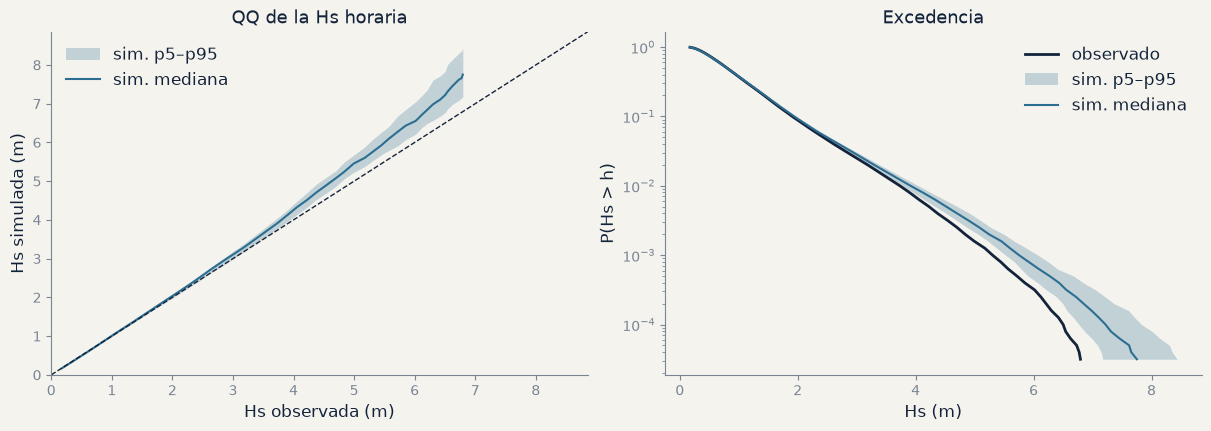

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
media,0.998,1.010,0.990,1.024,1.217,True
std,0.731,0.766,0.740,0.788,4.746,False
q50,0.796,0.796,0.783,0.810,0.059,True
q90,1.905,1.940,1.887,1.972,1.813,True
q99,3.731,3.912,3.774,4.045,4.853,False
q99.9,5.304,5.753,5.524,6.073,8.465,False


In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

#### QQ: cuantiles simulados frente a observados
qs = pila("q")
p5, p50, p95 = np.percentile(qs, [5, 50, 95], axis=0)
axs[0].fill_between(est_obs["q"], p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim. p5–p95")
axs[0].plot(est_obs["q"], p50, color=AZUL, lw=1.5, label="sim. mediana")
lim = [0, max(est_obs["q"].max(), p95.max()) * 1.05]
axs[0].plot(lim, lim, color=TINTA, lw=1, ls="--")
axs[0].set(xlabel="Hs observada (m)", ylabel="Hs simulada (m)", title="QQ de la Hs horaria", xlim=lim, ylim=lim)
axs[0].legend(frameon=False, loc="upper left")

#### Probabilidad de excedencia (cola en escala log)
axs[1].semilogy(est_obs["q"], 1 - Q_FINO, color=TINTA, lw=2, label="observado")
axs[1].fill_betweenx(1 - Q_FINO, p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim. p5–p95")
axs[1].semilogy(p50, 1 - Q_FINO, color=AZUL, lw=1.5, label="sim. mediana")
axs[1].set(xlabel="Hs (m)", ylabel="P(Hs > h)", title="Excedencia")
axs[1].legend(frameon=False)
fig.savefig(f"figuras/val_regimen_medio{SUF}.png", dpi=200)
plt.show()

#### Tabla
filas = [fila("media", "media"), fila("std", "std")]
for j, q in enumerate(Q_TABLA):
    k = np.argmin(np.abs(Q_FINO - q))
    o = est_obs["q"][k]; s = qs[:, k]; a, m, b = np.percentile(s, [5, 50, 95])
    filas.append({"métrica": f"q{q * 100:g}", "obs": o, "sim p50": m, "sim p5": a, "sim p95": b,
                  "sesgo %": 100 * (m - o) / o, "en banda": a <= o <= b})
tabla_regimen = pd.DataFrame(filas).set_index("métrica")
tabla_regimen.round(3)

#### 2. Persistencia: autocorrelación y duración de los temporales

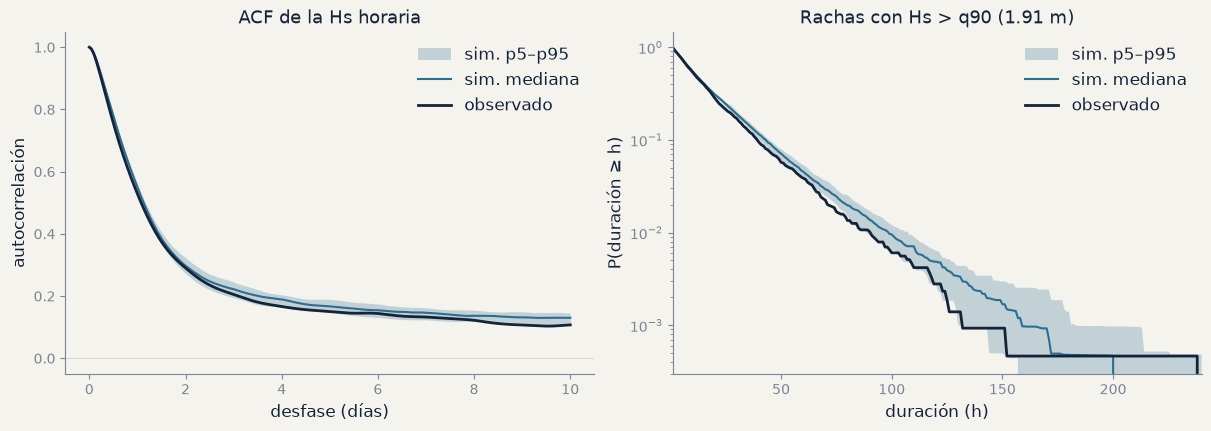

,obs,sim p50,sim p5,sim p95,en banda
métrica,,,,,
ACF 1 día,0.529,0.550,0.539,0.562,False
ACF 3 días,0.205,0.222,0.194,0.245,True
duración media > q90 (h),16.715,18.059,17.122,18.756,False


In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

#### ACF horaria hasta 10 días
dias = LAGS / 24
banda(axs[0], dias, pila("acf"))
axs[0].plot(dias, est_obs["acf"], color=TINTA, lw=2, label="observado")
axs[0].axhline(0, color="#DDD8CE", lw=0.8)
axs[0].set(xlabel="desfase (días)", ylabel="autocorrelación", title="ACF de la Hs horaria")
axs[0].legend(frameon=False)

#### Duración de las rachas por encima de q90: función de supervivencia
d_max = 240
x = np.arange(1, d_max + 1)
superv = lambda d: np.array([(d >= h).mean() for h in x])
banda(axs[1], x, np.array([superv(e["dur90"]) for e in est_sim]))
axs[1].semilogy(x, superv(est_obs["dur90"]), color=TINTA, lw=2, label="observado")
axs[1].set(xlabel="duración (h)", ylabel="P(duración ≥ h)", title=f"Rachas con Hs > q90 ({U90:.2f} m)", xlim=(1, d_max))
axs[1].set_yscale("log")
axs[1].legend(frameon=False)
fig.savefig(f"figuras/val_persistencia{SUF}.png", dpi=200)
plt.show()

#### Resumen numérico
dur_med = np.array([e["dur90"].mean() for e in est_sim])
acf24, acf72 = pila("acf")[:, 24], pila("acf")[:, 72]
tabla_persist = pd.DataFrame([
    {"métrica": "ACF 1 día", "obs": est_obs["acf"][24], "sim p50": np.median(acf24), "sim p5": np.percentile(acf24, 5), "sim p95": np.percentile(acf24, 95)},
    {"métrica": "ACF 3 días", "obs": est_obs["acf"][72], "sim p50": np.median(acf72), "sim p5": np.percentile(acf72, 5), "sim p95": np.percentile(acf72, 95)},
    {"métrica": "duración media > q90 (h)", "obs": est_obs["dur90"].mean(), "sim p50": np.median(dur_med), "sim p5": np.percentile(dur_med, 5), "sim p95": np.percentile(dur_med, 95)},
]).set_index("métrica")
tabla_persist["en banda"] = (tabla_persist["sim p5"] <= tabla_persist["obs"]) & (tabla_persist["obs"] <= tabla_persist["sim p95"])
tabla_persist.round(3)

#### 3. Estacionalidad (y ciclo diario, que el PVAR a 6 h no tiene)

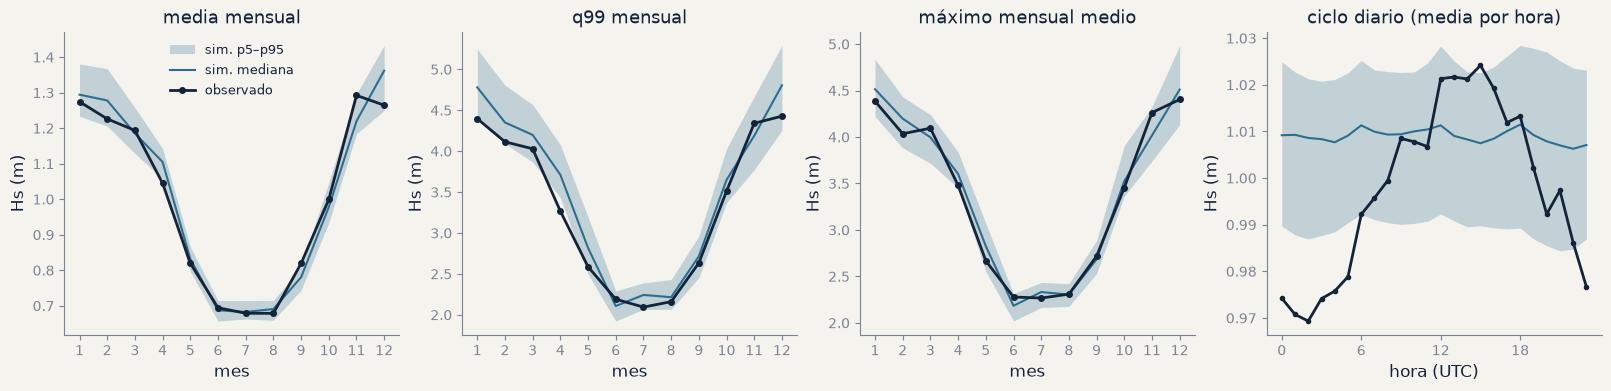

,1,2,3,4,5,6,7,8,9,10,11,12
mes_media,1.6,4.2,-0.7,5.7,1.5,-1.1,0.5,1.8,-4.7,-2.1,-5.6,7.7
mes_q90,2.3,3.3,-5.3,7.5,2.6,-1.2,3.5,1.2,-4.2,-0.4,-5.6,8.7
mes_q99,8.7,5.7,4.2,13.6,8.9,-3.8,7.1,2.6,3.1,3.9,-3.5,8.5
mes_max,2.9,4.0,-2.4,3.5,5.9,-4.1,2.9,-0.2,-1.3,2.0,-5.8,2.4


In [16]:
meses = np.arange(1, 13)
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
for ax, k, tit in zip(axs[:3], ["mes_media", "mes_q99", "mes_max"],
                      ["media mensual", "q99 mensual", "máximo mensual medio"]):
    banda(ax, meses, pila(k))
    ax.plot(meses, est_obs[k], "o-", color=TINTA, lw=2, ms=4, label="observado")
    ax.set(title=tit, xlabel="mes", ylabel="Hs (m)", xticks=meses)
axs[0].legend(frameon=False, fontsize=9)

horas = np.arange(24)
banda(axs[3], horas, pila("hora_media"))
axs[3].plot(horas, est_obs["hora_media"], "o-", color=TINTA, lw=2, ms=3)
axs[3].set(title="ciclo diario (media por hora)", xlabel="hora (UTC)", ylabel="Hs (m)", xticks=[0, 6, 12, 18])
fig.savefig(f"figuras/val_estacionalidad{SUF}.png", dpi=200)
plt.show()

#### Sesgo por mes (mediana simulada − observado), en %
pd.DataFrame({k: 100 * (np.median(pila(k), 0) - est_obs[k]) / est_obs[k] for k in ["mes_media", "mes_q90", "mes_q99", "mes_max"]},
             index=meses).round(1).T

#### 4. Variabilidad interanual
Si el emulador solo tuviera variabilidad de alta frecuencia, la dispersión entre años de la media o del q95 anual quedaría por debajo de la observada.

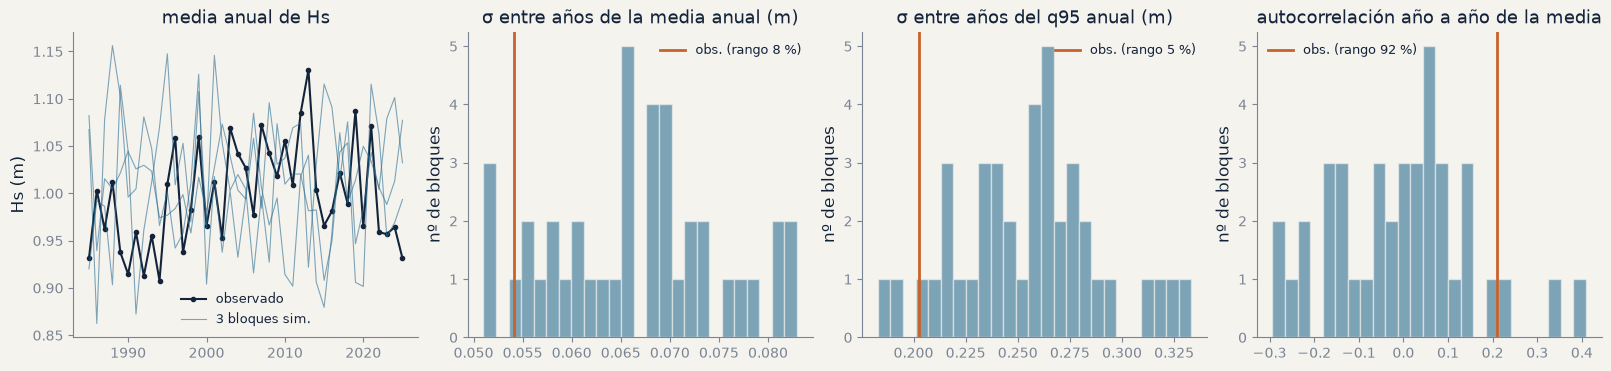

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
σ entre años de la media anual (m),0.054,0.067,0.052,0.082,23.843,True
σ entre años del q95 anual (m),0.203,0.258,0.203,0.318,27.352,False
autocorrelación año a año de la media,0.210,0.008,-0.240,0.221,-96.375,True


In [17]:
claves = [("std_anual_media", "σ entre años de la media anual (m)"),
          ("std_anual_q95", "σ entre años del q95 anual (m)"),
          ("ac1_anual_media", "autocorrelación año a año de la media")]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), constrained_layout=True)

#### Serie observada de medias anuales frente a la banda de un bloque simulado cualquiera
anos_obs = np.unique(obs.index.year)
axs[0].plot(anos_obs, est_obs["anual_media"], "o-", color=TINTA, lw=1.5, ms=3, label="observado")
for j in range(3):
    axs[0].plot(anos_obs, est_sim[j]["anual_media"], color=AZUL, lw=0.8, alpha=0.6, label="3 bloques sim." if j == 0 else None)
axs[0].set(title="media anual de Hs", ylabel="Hs (m)")
axs[0].legend(frameon=False, fontsize=9)

for ax, (k, tit) in zip(axs[1:], claves):
    v = pila(k)
    ax.hist(v, bins=25, color=AZUL, alpha=0.6, edgecolor=FONDO)
    ax.axvline(est_obs[k], color=NARANJA, lw=2, label=f"obs. (rango {rango(k):.0f} %)")
    ax.set(title=tit, ylabel="nº de bloques")
    ax.legend(frameon=False, fontsize=9)
fig.savefig(f"figuras/val_interanual{SUF}.png", dpi=200)
plt.show()

tabla_interanual = pd.DataFrame([fila(t, k) for k, t in claves]).set_index("métrica")
tabla_interanual.round(3)

#### 5. Extremos: máximos anuales, niveles de retorno y temporales

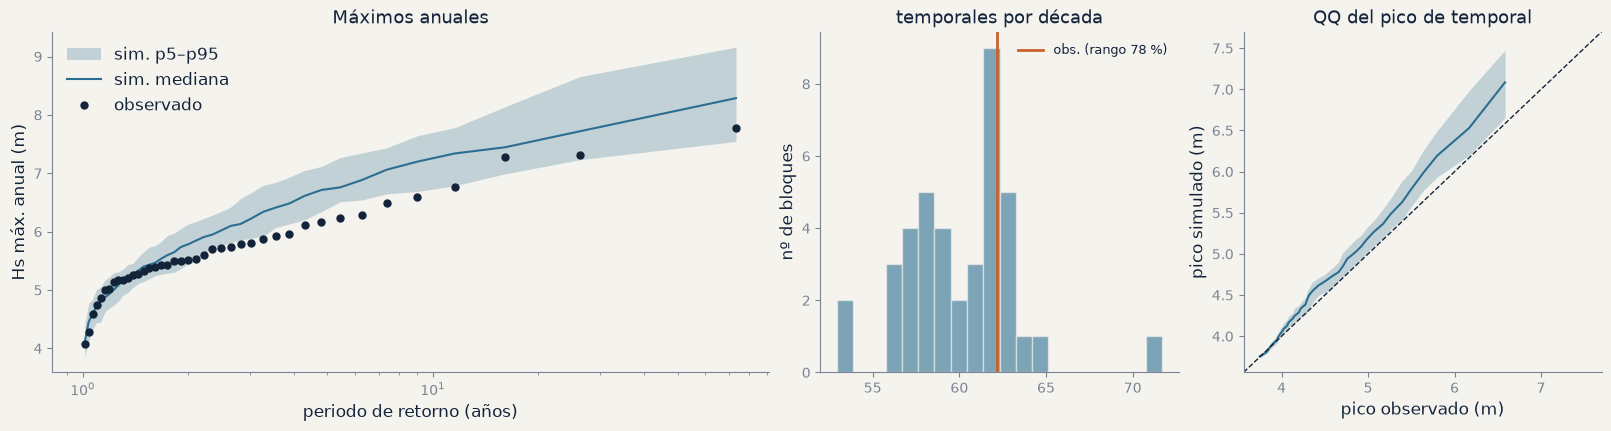

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
xi,-0.132,-0.134,-0.324,0.050,1.407,True
Hs2,5.589,5.802,5.481,6.067,3.807,True
Hs10,6.674,7.136,6.770,7.582,6.929,False
Hs50,7.426,8.113,7.403,8.970,9.250,True
Hs100,7.698,8.436,7.578,9.652,9.582,True
temporales / 10 años,62.195,60.488,56.207,63.927,-2.745,True


In [18]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True, gridspec_kw={"width_ratios": [2, 1, 1]})

#### Periodo de retorno empírico (Gringorten); misma N en obs. y bloques → misma posición
n = N_ANOS
T_emp = (n + 0.12) / (np.arange(1, n + 1) - 0.44)[::-1]
banda(axs[0], T_emp, pila("am"))
axs[0].plot(T_emp, est_obs["am"], "o", color=TINTA, ms=5, label="observado")
axs[0].set_xscale("log")
axs[0].set(xlabel="periodo de retorno (años)", ylabel="Hs máx. anual (m)", title="Máximos anuales")
axs[0].legend(frameon=False)

#### Temporales por década (picos > q99 separados 72 h)
v = pila("temporales_10a")
axs[1].hist(v, bins=20, color=AZUL, alpha=0.6, edgecolor=FONDO)
axs[1].axvline(est_obs["temporales_10a"], color=NARANJA, lw=2, label=f"obs. (rango {rango('temporales_10a'):.0f} %)")
axs[1].set(title="temporales por década", ylabel="nº de bloques")
axs[1].legend(frameon=False, fontsize=9)

#### Distribución del pico de los temporales (QQ)
qq = np.linspace(0.02, 0.98, 40)
pk_o = np.quantile(est_obs["picos"], qq)
pk_s = np.array([np.quantile(e["picos"], qq) for e in est_sim])
p5, p50, p95 = np.percentile(pk_s, [5, 50, 95], axis=0)
axs[2].fill_between(pk_o, p5, p95, color=AZUL, alpha=0.25, lw=0)
axs[2].plot(pk_o, p50, color=AZUL, lw=1.5)
lim = [pk_o.min() * 0.95, max(pk_o.max(), p95.max()) * 1.03]
axs[2].plot(lim, lim, color=TINTA, ls="--", lw=1)
axs[2].set(xlabel="pico observado (m)", ylabel="pico simulado (m)", title="QQ del pico de temporal", xlim=lim, ylim=lim)
fig.savefig(f"figuras/val_extremos{SUF}.png", dpi=200)
plt.show()

#### GEV por bloque de 41 años
tabla_extremos = pd.DataFrame([fila(k, k) for k in ["xi"] + [f"Hs{T}" for T in T_RET]] +
                              [fila("temporales / 10 años", "temporales_10a")]).set_index("métrica")
tabla_extremos.round(3)

#### 6. Resumen

In [19]:
resumen = pd.concat({"régimen medio": tabla_regimen, "persistencia": tabla_persist,
                     "interanual": tabla_interanual, "extremos": tabla_extremos})
print(f"{resumen['en banda'].sum()} de {len(resumen)} métricas dentro de la banda p5–p95")
resumen.round(3)

11 de 18 métricas dentro de la banda p5–p95


obs  sim p50  sim p5  \
              métrica                                                          
régimen medio media                                   0.998    1.010   0.990   
              std                                     0.731    0.766   0.740   
              q50                                     0.796    0.796   0.783   
              q90                                     1.905    1.940   1.887   
              q99                                     3.731    3.912   3.774   
              q99.9                                   5.304    5.753   5.524   
persistencia  ACF 1 día                               0.529    0.550   0.539   
              ACF 3 días                              0.205    0.222   0.194   
              duración media > q90 (h)               16.715   18.059  17.122   
interanual    σ entre años de la media anual (m)      0.054    0.067   0.052   
              σ entre años del q95 anual (m)          0.203    0.258   0.203   
              autocorrelación año a año de la media   0.210    0.008  -0.240   
extremos      xi                                     -0.132   -0.134  -0.324   
              Hs2                                     5.589    5.802   5.481   
              Hs10                                    6.674    7.136   6.770   
              Hs50                                    7.426    8.113   7.403   
              Hs100                                   7.698    8.436   7.578   
              temporales / 10 años                   62.195   60.488  56.207   

                                                     sim p95  sesgo %  \
              métrica                                                   
régimen medio media                                    1.024    1.217   
              std                                      0.788    4.746   
              q50                                      0.810    0.059   
              q90                                      1.972    1.813   
              q99                                      4.045    4.853   
              q99.9                                    6.073    8.465   
persistencia  ACF 1 día                                0.562      NaN   
              ACF 3 días                               0.245      NaN   
              duración media > q90 (h)                18.756      NaN   
interanual    σ entre años de la media anual (m)       0.082   23.843   
              σ entre años del q95 anual (m)           0.318   27.352   
              autocorrelación año a año de la media    0.221  -96.375   
extremos      xi                                       0.050    1.407   
              Hs2                                      6.067    3.807   
              Hs10                                     7.582    6.929   
              Hs50                                     8.970    9.250   
              Hs100                                    9.652    9.582   
              temporales / 10 años                    63.927   -2.745   

                                                     en banda  
              métrica                                          
régimen medio media                                      True  
              std                                       False  
              q50                                        True  
              q90                                        True  
              q99                                       False  
              q99.9                                     False  
persistencia  ACF 1 día                                 False  
              ACF 3 días                                 True  
              duración media > q90 (h)                  False  
interanual    σ entre años de la media anual (m)         True  
              σ entre años del q95 anual (m)            False  
              autocorrelación año a año de la media      True  
extremos      xi                                         True  
              Hs2                 

In [20]:
U95 = obs.quantile(0.95)
SEP_H = 48                                   # dos excedencias separadas más de 48 h son temporales distintos

def eventos(s, u, sep=SEP_H):
    """Temporales por excedencia de u, agrupados por rachas: duración, pico, energía, subida y bajada."""
    v = s.asfreq("h").values
    exc = np.flatnonzero(v > u)
    if len(exc) < 2:
        return pd.DataFrame(columns=["inicio", "dur", "pico", "energia", "subida", "bajada"])
    grupo = np.r_[0, np.cumsum(np.diff(exc) > sep)]
    filas = []
    for g in np.unique(grupo):
        i = exc[grupo == g]
        tramo = v[i[0]:i[-1] + 1]
        k = np.nanargmax(tramo)
        filas.append({"inicio": i[0], "dur": len(i), "pico": tramo[k],
                      "energia": np.nansum(v[i] ** 2), "subida": k, "bajada": len(tramo) - 1 - k})
    return pd.DataFrame(filas)

def theta_intervalos(s, u):
    """Índice extremal: estimador de intervalos de Ferro y Segers (2003)."""
    T = np.diff(np.flatnonzero(s.asfreq("h").values > u)).astype(float)
    if len(T) < 2:
        return np.nan
    N = len(T) + 1
    if T.max() <= 2:
        return min(1.0, 2 * T.sum() ** 2 / ((N - 1) * (T ** 2).sum()))
    return min(1.0, 2 * (T - 1).sum() ** 2 / ((N - 1) * ((T - 1) * (T - 2)).sum()))

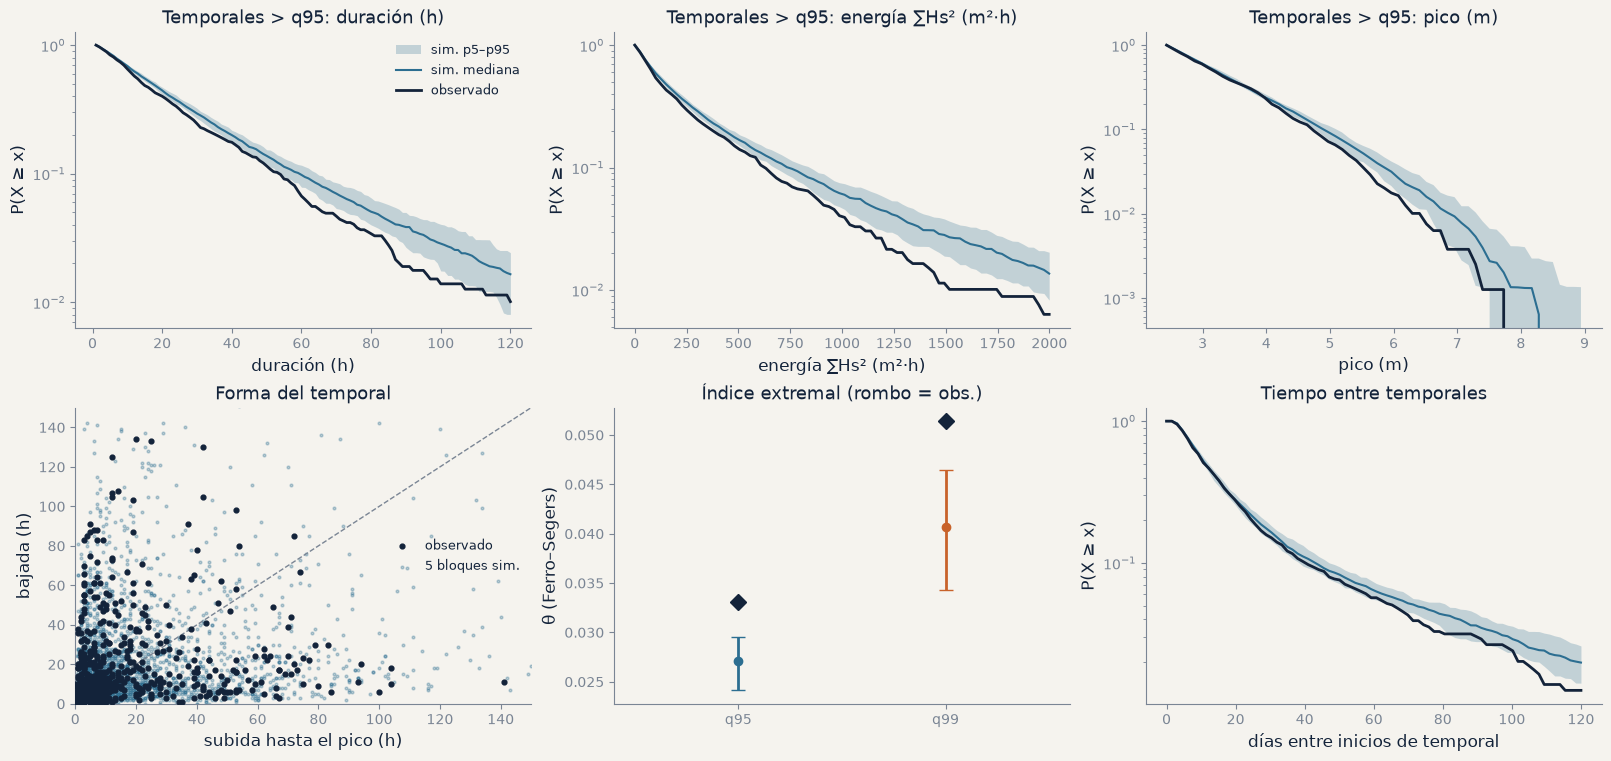

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
temporales > q95 / año,19.317,18.122,17.282,19.026,-6.187,False
dispersión nº/año (var/media),0.370,0.650,0.444,0.822,75.754,False
duración media (h),22.662,25.732,23.955,27.508,13.547,False
duración q90 (h),53.000,58.700,53.000,64.100,10.755,True
energía media,246.827,301.411,270.314,329.642,22.114,False
subida / bajada (mediana),0.667,0.850,0.768,0.990,27.572,False
θ q95,0.033,0.027,0.024,0.030,-18.017,False
θ q99,0.051,0.041,0.034,0.046,-20.952,False
temporales > q99 / año,6.293,5.988,5.504,6.318,-4.845,True


In [21]:
#### 5B. Temporales: duración, energía, forma, agrupamiento y cronología (umbral q95)
ev_o = est_obs["ev95"]
ev_s = [e["ev95"] for e in est_sim]
superv = lambda x, grid: np.array([(x >= g).mean() for g in grid])

fig, axs = plt.subplots(2, 3, figsize=(16, 7.5), constrained_layout=True)
for ax, col, tit, grid in [(axs[0, 0], "dur", "duración (h)", np.arange(1, 121)),
                           (axs[0, 1], "energia", "energía ∑Hs² (m²·h)", np.linspace(0, ev_o["energia"].quantile(.99) * 1.3, 80)),
                           (axs[0, 2], "pico", "pico (m)", np.linspace(U95, ev_o["pico"].max() * 1.15, 60))]:
    banda(ax, grid, np.array([superv(d[col].values, grid) for d in ev_s]))
    ax.semilogy(grid, superv(ev_o[col].values, grid), color=TINTA, lw=2, label="observado")
    ax.set(title=f"Temporales > q95: {tit}", xlabel=tit, ylabel="P(X ≥ x)")
axs[0, 0].legend(frameon=False, fontsize=9)

#### Forma: subida frente a bajada
axs[1, 0].scatter(ev_o["subida"], ev_o["bajada"], s=12, color=TINTA, label="observado", zorder=3)
d0 = pd.concat(ev_s[:5])
axs[1, 0].scatter(d0["subida"], d0["bajada"], s=4, color=AZUL, alpha=0.3, label="5 bloques sim.")
axs[1, 0].plot([0, 150], [0, 150], color=GRIS, ls="--", lw=1)
axs[1, 0].set(xlim=(0, 150), ylim=(0, 150), xlabel="subida hasta el pico (h)", ylabel="bajada (h)", title="Forma del temporal")
axs[1, 0].legend(frameon=False, fontsize=9)

#### Índice extremal
for j, (q, c) in enumerate([(95, AZUL), (99, NARANJA)]):
    v = pila(f"theta_q{q}"); p5, p50, p95 = np.percentile(v, [5, 50, 95])
    axs[1, 1].errorbar(j, p50, yerr=[[p50 - p5], [p95 - p50]], fmt="o", color=c, capsize=5, lw=2)
    axs[1, 1].plot(j, est_obs[f"theta_q{q}"], "D", color=TINTA, ms=8)
axs[1, 1].set(xticks=[0, 1], xticklabels=["q95", "q99"], xlim=(-0.6, 1.6), ylabel="θ (Ferro–Segers)",
              title="Índice extremal (rombo = obs.)")

#### Tiempo entre temporales
ia = lambda d: np.diff(d["inicio"].values) / 24
grid = np.linspace(0, 120, 80)
banda(axs[1, 2], grid, np.array([superv(ia(d), grid) for d in ev_s]))
axs[1, 2].semilogy(grid, superv(ia(ev_o), grid), color=TINTA, lw=2)
axs[1, 2].set(xlabel="días entre inicios de temporal", ylabel="P(X ≥ x)", title="Tiempo entre temporales")
fig.savefig(f"figuras/val_temporales{SUF}.png", dpi=200)
plt.show()

#### Tabla
def fila_ev(nombre, f_obs, f_sim):
    s = np.array([f_sim(e) for e in est_sim]); o = f_obs(est_obs)
    a, m, b = np.percentile(s, [5, 50, 95])
    return {"métrica": nombre, "obs": o, "sim p50": m, "sim p5": a, "sim p95": b,
            "sesgo %": 100 * (m - o) / o if o else np.nan, "en banda": a <= o <= b}
tabla_temp = pd.DataFrame([
    fila_ev("temporales > q95 / año",   lambda e: len(e["ev95"]) / N_ANOS, lambda e: len(e["ev95"]) / N_ANOS),
    fila_ev("dispersión nº/año (var/media)", lambda e: e["n_ev95_ano"].var() / e["n_ev95_ano"].mean(),
                                             lambda e: e["n_ev95_ano"].var() / e["n_ev95_ano"].mean()),
    fila_ev("duración media (h)",        lambda e: e["ev95"]["dur"].mean(), lambda e: e["ev95"]["dur"].mean()),
    fila_ev("duración q90 (h)",          lambda e: e["ev95"]["dur"].quantile(.9), lambda e: e["ev95"]["dur"].quantile(.9)),
    fila_ev("energía media",             lambda e: e["ev95"]["energia"].mean(), lambda e: e["ev95"]["energia"].mean()),
    fila_ev("subida / bajada (mediana)", lambda e: (e["ev95"]["subida"] / e["ev95"]["bajada"].clip(lower=1)).median(),
                                         lambda e: (e["ev95"]["subida"] / e["ev95"]["bajada"].clip(lower=1)).median()),
    fila_ev("θ q95", lambda e: e["theta_q95"], lambda e: e["theta_q95"]),
    fila_ev("θ q99", lambda e: e["theta_q99"], lambda e: e["theta_q99"]),
    fila_ev("temporales > q99 / año",   lambda e: len(e["ev99"]) / N_ANOS, lambda e: len(e["ev99"]) / N_ANOS),
]).set_index("métrica")
tabla_temp.round(3)

In [22]:
#### Misma validación con la salida del 07 (f histórica + ruido, sin PVAR): ¿el fallo es del PVAR?
obj = pickle.load(open(f"outputs/xgb_pit_{point}/hs_sims_1985_2025{SUF}.pkl", "rb"))
if isinstance(obj, dict):
    obj = obj.get("hs_sims", next(iter(obj.values())))
if isinstance(obj, pd.DataFrame):
    series_07 = [obj[c] for c in obj.columns]
else:
    series_07 = list(obj)

est_07 = []
for s in series_07:
    s = s.astype("float64").loc["1985":"2025"]
    s = s[s.index.year.isin(np.unique(obs.index.year))]       # mismos años que la observación
    est_07.append(estadisticos(s))
print(f"{len(est_07)} simulaciones del 07")

#### Para reutilizar la celda 5B tal cual: cambia est_sim, ejecuta la 5B y luego vuelve a dejarlo
est_sim_08 = est_sim
est_sim = est_07          # ← ahora ejecuta otra vez la celda 5B (y cambia el nombre de la figura a ..._07)

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/xgb_pit_p102/hs_sims_1985_2025_simple_est_fqm.pkl'

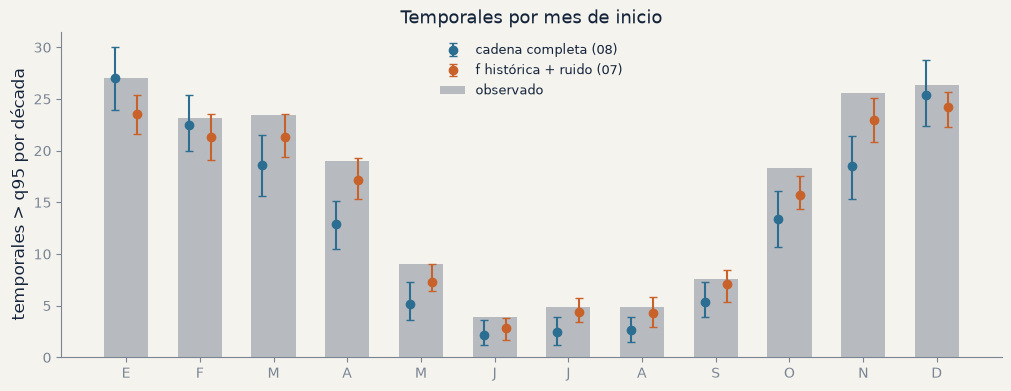

          1     2     3     4    5    6    7    8    9     10    11    12
obs     27.1  23.2  23.4  19.0  9.0  3.9  4.9  4.9  7.6  18.3  25.6  26.3
08 p50  27.1  22.4  18.7  12.9  5.1  2.2  2.4  2.7  5.4  13.4  18.5  25.4
07 p50  23.5  21.3  21.3  17.2  7.3  2.8  4.4  4.3  7.1  15.7  22.9  24.3


In [ ]:
#### Temporales > q95 por mes (por década): ¿faltan en primavera/otoño?
def por_mes(e, s_index):
    """Nº de temporales > q95 por mes de inicio, por década."""
    ini = e["ev95"]["inicio"].astype(int).values
    n_anos = len(np.unique(s_index.year))
    return np.bincount(s_index[ini].month, minlength=13)[1:] * 10 / n_anos

mo = por_mes(est_obs, obs.asfreq("h").index)
#### índices horarios de cada bloque / simulación para traducir 'inicio' a fecha
def indices_08():
    out = []
    for fic in ficheros:
        hs = pd.read_parquet(fic, columns=["VHM0"])["VHM0"]
        anos = np.unique(hs.index.year); anos = anos[[hs.loc[str(a)].size >= 8700 for a in anos]]
        for b in range(len(anos) // N_ANOS):
            out.append(hs[hs.index.year.isin(anos[b * N_ANOS:(b + 1) * N_ANOS])].asfreq("h").index)
    return out
idx_08 = indices_08()
m08 = np.array([por_mes(e, ix) for e, ix in zip(est_sim_08, idx_08)])
m07 = np.array([por_mes(e, s.loc["1985":"2025"].asfreq("h").index) for e, s in zip(est_07, series_07)])

meses = np.arange(1, 13)
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
for arr_, c, lab, dx in [(m08, AZUL, "cadena completa (08)", -0.15), (m07, NARANJA, "f histórica + ruido (07)", 0.15)]:
    p5, p50, p95 = np.percentile(arr_, [5, 50, 95], axis=0)
    ax.errorbar(meses + dx, p50, yerr=[p50 - p5, p95 - p50], fmt="o", color=c, capsize=3, lw=1.5, label=lab)
ax.bar(meses, mo, width=0.6, color=GRIS, alpha=0.5, label="observado")
ax.set(xticks=meses, xticklabels=["E","F","M","A","M","J","J","A","S","O","N","D"],
       ylabel="temporales > q95 por década", title="Temporales por mes de inicio")
ax.legend(frameon=False, fontsize=9)
fig.savefig(f"figuras/val_temporales_mes{SUF}.png", dpi=200)
plt.show()

print(pd.DataFrame({"obs": mo, "08 p50": np.median(m08, 0), "07 p50": np.median(m07, 0)},
                   index=meses).round(1).T)

In [ ]:
#### ¿Faltan horas por encima de q95 o faltan episodios? (por mes, por década)
def horas_mes(s_values, s_index, u):
    n_anos = len(np.unique(s_index.year))
    return np.bincount(s_index[s_values > u].month, minlength=13)[1:] * 10 / n_anos

obs_h = obs.asfreq("h")
h_obs = horas_mes(obs_h.values, obs_h.index, U95)
h_07 = np.array([horas_mes(s.loc["1985":"2025"].values, s.loc["1985":"2025"].index, U95) for s in series_07])

tabla = pd.DataFrame({
    "horas obs": h_obs, "horas 07": np.median(h_07, 0),
    "episodios obs": mo, "episodios 07": np.median(m07, 0)}, index=meses)
tabla["h/episodio obs"] = tabla["horas obs"] / tabla["episodios obs"]
tabla["h/episodio 07"] = tabla["horas 07"] / tabla["episodios 07"]
tabla.round(1).T

,1,2,3,4,5,6,7,8,9,10,11,12
horas obs,766.3,618.0,622.7,301.2,112.2,43.4,29.0,32.7,106.1,335.9,682.9,727.1
horas 07,780.6,598.8,604.0,347.2,112.7,28.0,46.8,49.0,100.1,300.9,639.4,700.7
episodios obs,27.1,23.2,23.4,19.0,9.0,3.9,4.9,4.9,7.6,18.3,25.6,26.3
episodios 07,23.5,21.3,21.3,17.2,7.3,2.8,4.4,4.3,7.1,15.7,22.9,24.3
h/episodio obs,28.3,26.7,26.6,15.8,12.4,11.1,6.0,6.7,14.0,18.4,26.7,27.6
h/episodio 07,33.2,28.1,28.3,20.2,15.4,10.0,10.7,11.5,14.2,19.1,27.9,28.9
